# Fase 6 e 7 — Placar e cinco erros
As três configurações nas 45 perguntas de teste, com o critério de `avaliacao/criterio.md`.

In [1]:
import sys, os
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "src"))
sys.path.insert(0, str(RAIZ / "scripts"))
print(RAIZ)

C:\Users\Gusma\OneDrive\Documentos\Estudos\passo-seguro\passo-seguro-genai


In [2]:
%run avaliacao/avaliar.py

W1108 16:05:25.857000 34604 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

45 perguntas (teste); limiar=0.17; top_k=3; base=qwen2.5:1.5b-instruct; lora=passo-seguro-lora



--- A — modelo sem contexto ---


  45/45 n20 --   0.3s
{"n": 45, "exatidao": 0.233, "citacao_correta": 0.0, "recusa_indevida": 0.0, "taxa_alucinacao": 1.0, "recusa_correta_nao_consta": 0.0, "json_valido": 1.0, "latencia_media_s": 0.3}

--- B — RAG simples ---


  45/45 n20 ok   0.0s
{"n": 45, "exatidao": 0.433, "citacao_correta": 0.5, "recusa_indevida": 0.233, "taxa_alucinacao": 0.356, "recusa_correta_nao_consta": 0.8, "json_valido": 0.978, "latencia_media_s": 0.35}

--- C — RAG + LoRA ---


  45/45 n20 ok   0.0s
{"n": 45, "exatidao": 0.4, "citacao_correta": 0.533, "recusa_indevida": 0.233, "taxa_alucinacao": 0.289, "recusa_correta_nao_consta": 0.867, "json_valido": 1.0, "latencia_media_s": 0.23}

| Configuração | Exatidão | Citação correta | Alucinação | Recusa correta (não consta) | Recusa indevida | JSON válido | Latência média (s) |
|---|---|---|---|---|---|---|---|
| A — modelo sem contexto | 23% | 0% | 100% | 0% | 0% | 100% | 0.3 |
| B — RAG simples | 43% | 50% | 36% | 80% | 23% | 98% | 0.35 |
| C — RAG + LoRA | 40% | 53% | 29% | 87% | 23% | 100% | 0.23 |

45 perguntas do split `teste`; limiar 0.17; top-3; 0 julgamentos corrigidos à mão.

Interpretação (2–3 frases por diferença): onde o LoRA ganhou, onde não ganhou e por quê; o efeito do RAG sobre a alucinação; o custo em recusas indevidas; formal × informal (ver placar_por_registro.csv).

Saídas em C:\Users\Gusma\OneDrive\Documentos\Estudos\passo-seguro\passo-seguro-genai\avaliacao\resultados. Próximo: python script

,n,exatidao,citacao_correta,taxa_alucinacao,recusa_correta_nao_consta,recusa_indevida,json_valido,latencia_media_s
config,,,,,,,,
A — modelo sem contexto,45,0.233,0.000,1.000,0.000,0.000,1.000,0.30
B — RAG simples,45,0.433,0.500,0.356,0.800,0.233,0.978,0.35
C — RAG + LoRA,45,0.400,0.533,0.289,0.867,0.233,1.000,0.23


<Axes: title={'center': 'Placar (45 perguntas de teste)'}, xlabel='config'>

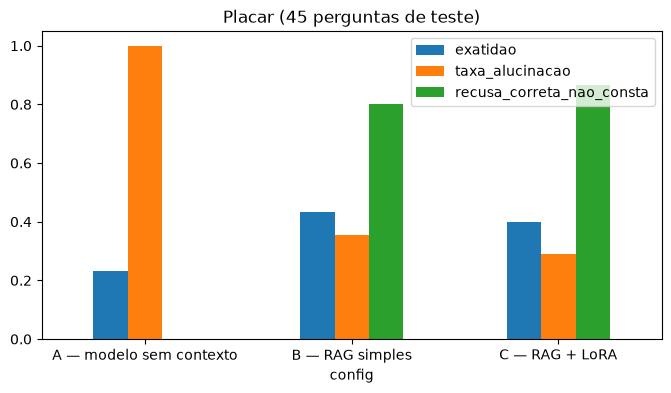

In [3]:
import pandas as pd
p = pd.read_csv('avaliacao/resultados/placar.csv').set_index('config')
display(p)
p[['exatidao','taxa_alucinacao','recusa_correta_nao_consta']].plot.bar(rot=0, figsize=(8,4), title='Placar (45 perguntas de teste)')

In [4]:
display(pd.read_csv('avaliacao/resultados/placar_por_registro.csv'))  # viés: formal × informal

,config,registro,n,exatidao,citacao_correta,taxa_alucinacao,recusa_correta_nao_consta,recusa_indevida,json_valido,latencia_media_s
0,A — modelo sem contexto,formal,17,0.333,0.000,1.000,0.0,0.000,1.000,0.37
1,A — modelo sem contexto,informal,28,0.167,0.000,1.000,0.0,0.000,1.000,0.26
2,B — RAG simples,formal,17,0.667,0.667,0.471,0.6,0.000,1.000,0.38
3,B — RAG simples,informal,28,0.278,0.389,0.286,0.9,0.389,0.964,0.33
4,C — RAG + LoRA,formal,17,0.667,0.667,0.235,0.8,0.083,1.000,0.27
5,C — RAG + LoRA,informal,28,0.222,0.444,0.321,0.9,0.333,1.000,0.20


**Interpretação** (2–3 frases por diferença): A→B (efeito do RAG), B→C (efeito do LoRA: onde ganhou, onde não ganhou e por quê), custo em recusas indevidas, formal × informal.

In [5]:
%run scripts/10_erros.py --config C

20 erros: {'busca_nao_achou': 5, 'recusa_por_limiar': 4, 'trecho_mal_cortado': 8, 'modelo_recusou_com_base': 1, 'modelo_inventou': 2} -> avaliacao/resultados/erros_candidatos.md


In [6]:
from IPython.display import Markdown
Markdown(open('avaliacao/resultados/erros_candidatos.md', encoding='utf-8').read()[:6000])

# Erros candidatos — configuração C

20 erros em 45 perguntas: {'busca_nao_achou': 5, 'recusa_por_limiar': 4, 'trecho_mal_cortado': 8, 'modelo_recusou_com_base': 1, 'modelo_inventou': 2}

## r06 — busca_nao_achou
- **Pergunta:** se o dono não arrumar a calçada ele leva multa? de quanto?
- **Esperado:** Sim. A multa é de R$ 300,00 por metro linear da testada (ou do trecho danificado), corrigida anualmente pelo IPCA. (`sp-lei15442-anexo|sp-lei15442-art15`)
- **Saída:** Sim. A multa é aplicável à pessoa que tem responsabilidade pela calçada, seja ela proprietária ou responsável pelo imóvel.
- **Fontes citadas:** ['sp-subpref-calcadas-s01-p2'] · recusou=False · nível=None
- **Recuperados:** [['sp-subpref-calcadas-s01-p4', 0.3912], ['sp-subpref-calcadas-s01-p2', 0.1181], ['sp-dec59671-art1-p1', 0.0232]]

## r12 — busca_nao_achou
- **Pergunta:** a raiz da árvore levantou a calçada, o dono é obrigado a consertar?
- **Esperado:** O responsável fica temporariamente dispensado da manutenção enquanto a árvore que causou o dano não for removida. (`sp-dec59671-art32`)
- **Saída:** Não encontrei isso nas fontes oficiais que eu consulto. Para falar com a Prefeitura, ligue 156 ou acesse o SP156: https://sp156.prefeitura.sp.gov.br/ — e você pode registrar o problema aqui no Passo Seguro.
- **Fontes citadas:** [] · recusou=True · nível=busca
- **Recuperados:** [['sp-dec59671-art34-p1', 0.0305], ['sp-subpref-calcadas-s01-p4', 0.0228], ['sp-dec59671-art1-p1', 0.0175]]

## r21 — busca_nao_achou
- **Pergunta:** de quem é a responsabilidade pela segurança do pedestre no trânsito?
- **Esperado:** Os veículos maiores respondem pelos menores, os motorizados pelos não motorizados e, juntos, pela segurança dos pedestres. (`ctb-art29`)
- **Saída:** É assegurada ao pedestre a utilização dos passeios ou passagens apropriadas das vias urbanas e dos acostamentos das vias rurais para circulação, podendo a autoridade competente permitir a utilização de parte da calçada para outros fins, desde que não seja prejudicial ao fluxo de pedestres.
- **Fontes citadas:** ['sp-subpref-calcadas-s01-p2'] · recusou=False · nível=None
- **Recuperados:** [['sp-subpref-calcadas-s01-p2', 0.6335], ['ctb-art68-p1', 0.5251], ['sp-subpref-calcadas-s01-p1', 0.2066]]

## r26 — busca_nao_achou
- **Pergunta:** E se a calçada danificada for de uma praça ou prédio público?
- **Esperado:** O serviço 'Calçada pública - solicitar manutenção', pelo 156. (`sp-subpref-servicos156`)
- **Saída:** A calçada da praça ou prédio público é responsabilidade do responsável pelo imóvel, seja ele proprietário ou usuário.
- **Fontes citadas:** ['sp-subpref-calcadas-s01-p4'] · recusou=False · nível=None
- **Recuperados:** [['sp-subpref-calcadas-s01-p2', 0.5587], ['sp-subpref-calcadas-s01-p4', 0.3234], ['sp-dec59671-art1-p1', 0.1666]]

## r34 — busca_nao_achou
- **Pergunta:** a rampa da garagem do vizinho deixou a calçada torta, pode isso?
- **Esperado:** Não. O rebaixamento para acesso de veículos não pode obstruir a faixa livre nem alterar a sua inclinação transversal. (`sp-dec59671-art10`)
- **Saída:** Não encontrei isso nas fontes oficiais que eu consulto. Para falar com a Prefeitura, ligue 156 ou acesse o SP156: https://sp156.prefeitura.sp.gov.br/ — e você pode registrar o problema aqui no Passo Seguro.
- **Fontes citadas:** [] · recusou=True · nível=busca
- **Recuperados:** [['sp-cartilha-calcadas-s04-p1', 0.0185], ['sp-cartilha-calcadas-s05-p1', 0.0136], ['sp-dec59671-art1-p1', 0.0047]]

## n03 — modelo_inventou
- **Pergunta:** Quantos dias a Prefeitura leva para consertar uma calçada pública?
- **Esperado:** Recusa: a base não traz essa informação. (`None`)
- **Saída:** A Prefeitura tem 30 dias para regularizar as calçadas que foram feitas pela empresa concessionária.
- **Fontes citadas:** ['sp-subpref-calcadas-s01-p4'] · recusou=False · nível=None
- **Recuperados:** [['sp-subpref-calcadas-s01-p4', 0.5959], ['sp-dec59671-art32-p1', 0.5485], ['sp-subpref-calcadas-s01-p2', 0.1055]]

## n18 — modelo_inventou
- **Pergunta:** se eu mesmo consertar a calçada da praça a prefeitura me reembolsa?
- **Esperado:** Recusa: a base não traz essa informação. (`None`)
- **Saída:** Sim, o cidadão é responsável pela manutenção após reforma. A Prefeitura executa as reformas e paga, mas depois fica sob responsabilidade do cidadão.
- **Fontes citadas:** ['sp-subpref-calcadas-s01-p4'] · recusou=False · nível=None
- **Recuperados:** [['sp-subpref-calcadas-s01-p2', 0.2595], ['sp-subpref-calcadas-s01-p4', 0.2201], ['sp-cartilha-calcadas-s01-p1', 0.109]]

## r20 — modelo_recusou_com_base
- **Pergunta:** Quem fiscaliza e multa o estacionamento irregular na cidade?
- **Esperado:** Os órgãos executivos de trânsito do município, dentro da sua circunscrição. (`ctb-art24`)
- **Saída:** Não encontrei isso nas fontes oficiais que eu consulto. Para falar com a Prefeitura, ligue 156 ou acesse o SP156: https://sp156.prefeitura.sp.gov.br/ — e você pode registrar o problema aqui no Passo Seguro.
- **Fontes citadas:** [] · recusou=True · nível=modelo
- **Recuperados:** [['sp-subpref-servicos156-s01-p3', 0.3283], ['ctb-art24-p1', 0.2848], ['sp-lei15442-art12-p1', 0.2482]]

## r08 — recusa_por_limiar
- **Pergunta:** e se o dono nunca arrumar, a prefeitura faz a obra?
- **Esperado:** A Prefeitura pode executar a obra e cobrar o custo do responsável, além das multas. (`sp-lei15442-art17`)
- **Saída:** Não encontrei isso nas fontes oficiais que eu consulto. Para falar com a Prefeitura, ligue 156 ou acesse o SP156: https://sp156.prefeitura.sp.gov.br/ — e você pode registrar o problema aqui no Passo Seguro.
- **Fontes citadas:** [] · recusou=True · nível=busca
- **Recuperados:** [['sp-dec59671-art1-p1', 0.0645], ['sp-lei15442-art17-p1', 0.0278], ['sp-lei15442-art10-p1', 0.0212]]

## r11 — recusa_por_limiar
- **Pergunta:** a empresa de água quebrou a calçada pra mexer no cano e deixou assim, quem conserta?
- **Esperado:** Quem usa a via para instalar infraestrutura tem de reparar os danos que causou à calçad